In [ ]:
# LE JEU DE TEST

In [13]:
# Configuration du générateur pour le jeu de test
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_gen_df,
    x_col="filepath",
    y_col="target_str",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode="grayscale",
    class_mode="binary",
    classes=["0", "1"],
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Validation de la cohérence du nombre d'images attendues (4233 pour le test)
assert test_generator.n == 4233, f"Erreur : {test_generator.n} au lieu de 4233 images de test"
print("Nombre de lots (batches) pour le test :", len(test_generator))

Found 4233 validated image filenames belonging to 2 classes.
Nombre de lots (batches) pour le test : 133


In [14]:
# Chargement du meilleur modèle et prédiction sur le jeu de test
best_model = tf.keras.models.load_model(str(checkpoint_path))
test_generator.reset()

y_proba_test = best_model.predict(test_generator, verbose=1).ravel()
y_pred_test = (y_proba_test >= 0.5).astype(int)
y_true_test = np.asarray(test_generator.classes)

assert len(y_true_test) == len(y_pred_test) == 4233

# Affichage du rapport de classification
print("Rapport de classification sur le jeu de TEST :")
print(classification_report(y_true_test, y_pred_test, target_names=["Non-COVID", "COVID"], digits=4))

133/133 ━━━━━━━━━━━━━━━━━━━━ 1440s 11s/step
Rapport de classification sur le jeu de TEST :
              precision    recall  f1-score   support

   Non-COVID     0.9882    0.9567    0.9722      3510
       COVID     0.8180    0.9447    0.8768       723

    accuracy                         0.9546      4233
   macro avg     0.9031    0.9507    0.9245      4233
weighted avg     0.9591    0.9546    0.9559      4233



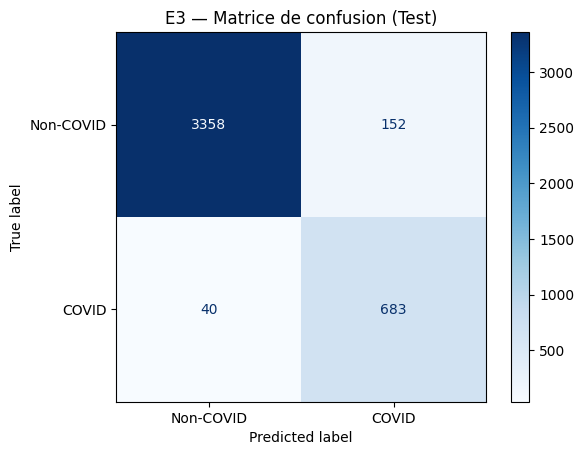

Résultats et métriques de test sauvegardés avec succès.


In [15]:
# Matrice de confusion pour le jeu de test
cm_test = confusion_matrix(y_true_test, y_pred_test, labels=[0, 1])
ConfusionMatrixDisplay(cm_test, display_labels=["Non-COVID", "COVID"]).plot(cmap="Blues")
plt.title("E3 — Matrice de confusion (Test)")
plt.savefig(OUTPUT_DIR / "E3_confusion_test.png", dpi=180, bbox_inches="tight")
plt.show()

# Sauvegarde des prédictions détaillées et du rapport de performance
pd.DataFrame({
    "filepath": test_gen_df["filepath"].to_numpy(),
    "y_true": y_true_test,
    "y_proba": y_proba_test,
    "y_pred": y_pred_test
}).to_csv(OUTPUT_DIR / "E3_predictions_test.csv", index=False)

pd.DataFrame(classification_report(y_true_test, y_pred_test,
    target_names=["Non-COVID", "COVID"], output_dict=True)).T.to_csv(
    OUTPUT_DIR / "E3_classification_report_test.csv")

print("Résultats et métriques de test sauvegardés avec succès.")

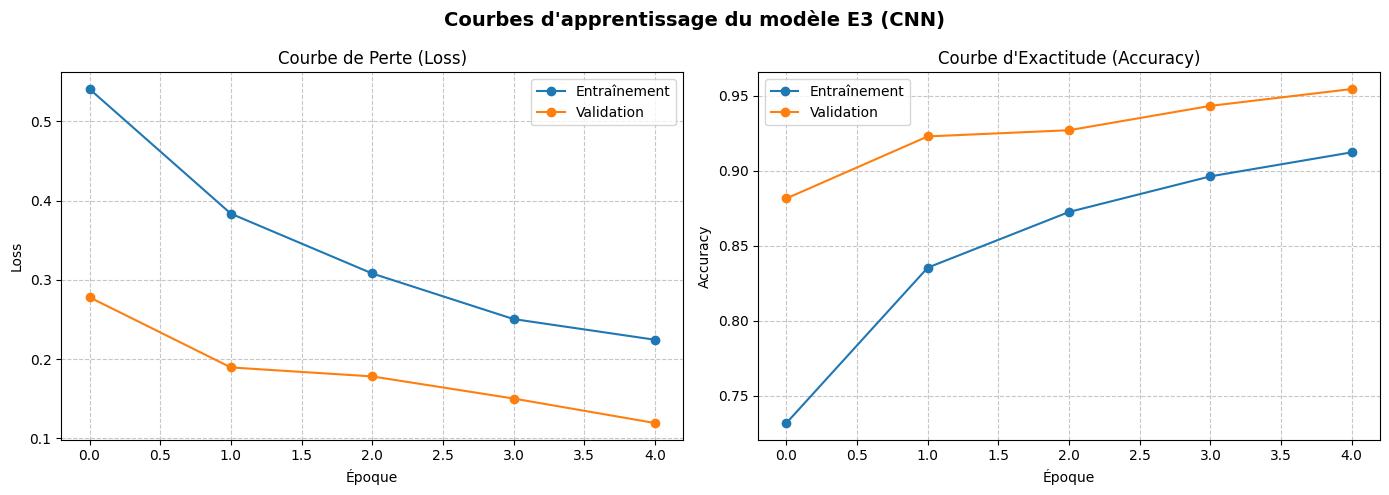

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Charger l'historique d'entraînement
history_path = OUTPUT_DIR / "E3_history.csv"
history_df = pd.read_csv(history_path)

# Création de la figure pour les courbes d'apprentissage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Tracer la courbe de Loss (Perte)
ax1.plot(history_df['loss'], label='Entraînement', marker='o')
ax1.plot(history_df['val_loss'], label='Validation', marker='o')
ax1.set_title('Courbe de Perte (Loss)')
ax1.set_xlabel('Époque')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend()

# Tracer la courbe d'Accuracy (Exactitude)
ax2.plot(history_df['accuracy'], label='Entraînement', marker='o')
ax2.plot(history_df['val_accuracy'], label='Validation', marker='o')
ax2.set_title('Courbe d\'Exactitude (Accuracy)')
ax2.set_xlabel('Époque')
ax2.set_ylabel('Accuracy')
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()

plt.suptitle('Courbes d\'apprentissage du modèle E3 (CNN)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "E3_learning_curves.png", dpi=180, bbox_inches="tight")
plt.show()

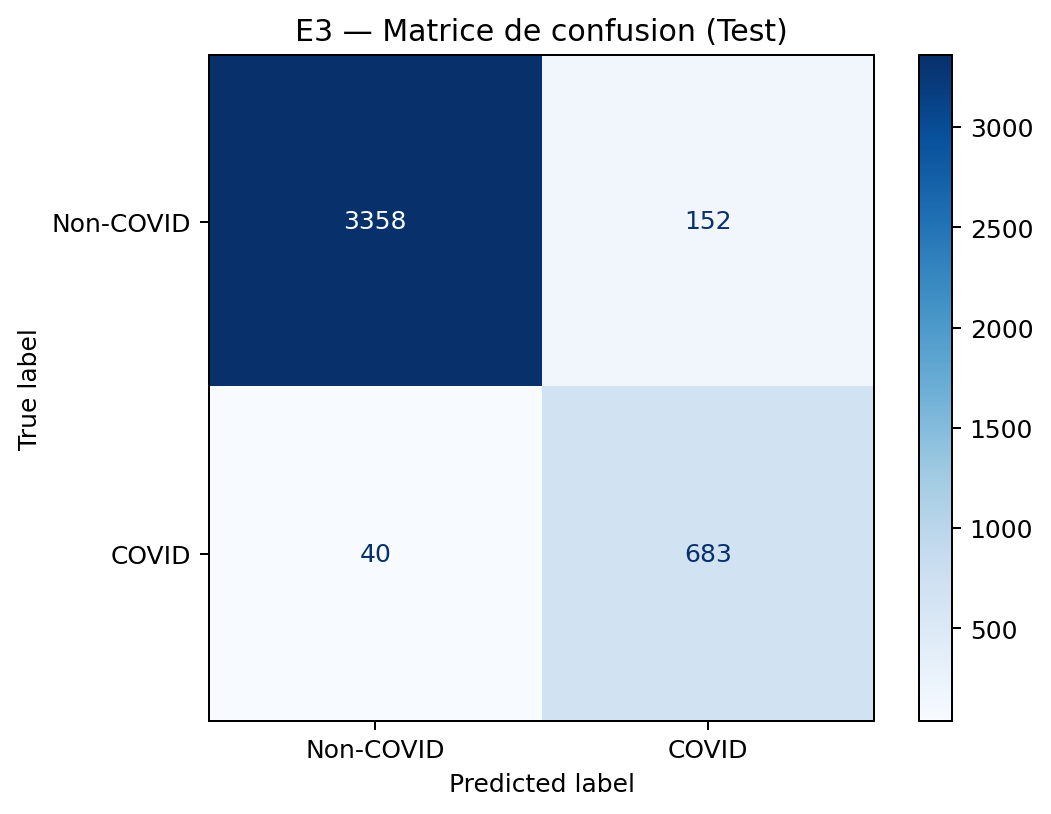

In [17]:
from IPython.display import Image, display
import os

confusion_matrix_path = "E3_confusion_test.png"
if os.path.exists(confusion_matrix_path):
    display(Image(filename=confusion_matrix_path))
else:
    # Recréer la matrice de confusion si l'image n'est pas trouvée
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    import matplotlib.pyplot as plt
    import numpy as np

    cm_test = confusion_matrix(y_true_test, y_pred_test, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=["Non-COVID", "COVID"])
    disp.plot(cmap="Blues")
    plt.title("E3 — Matrice de confusion (Test)")
    plt.show()

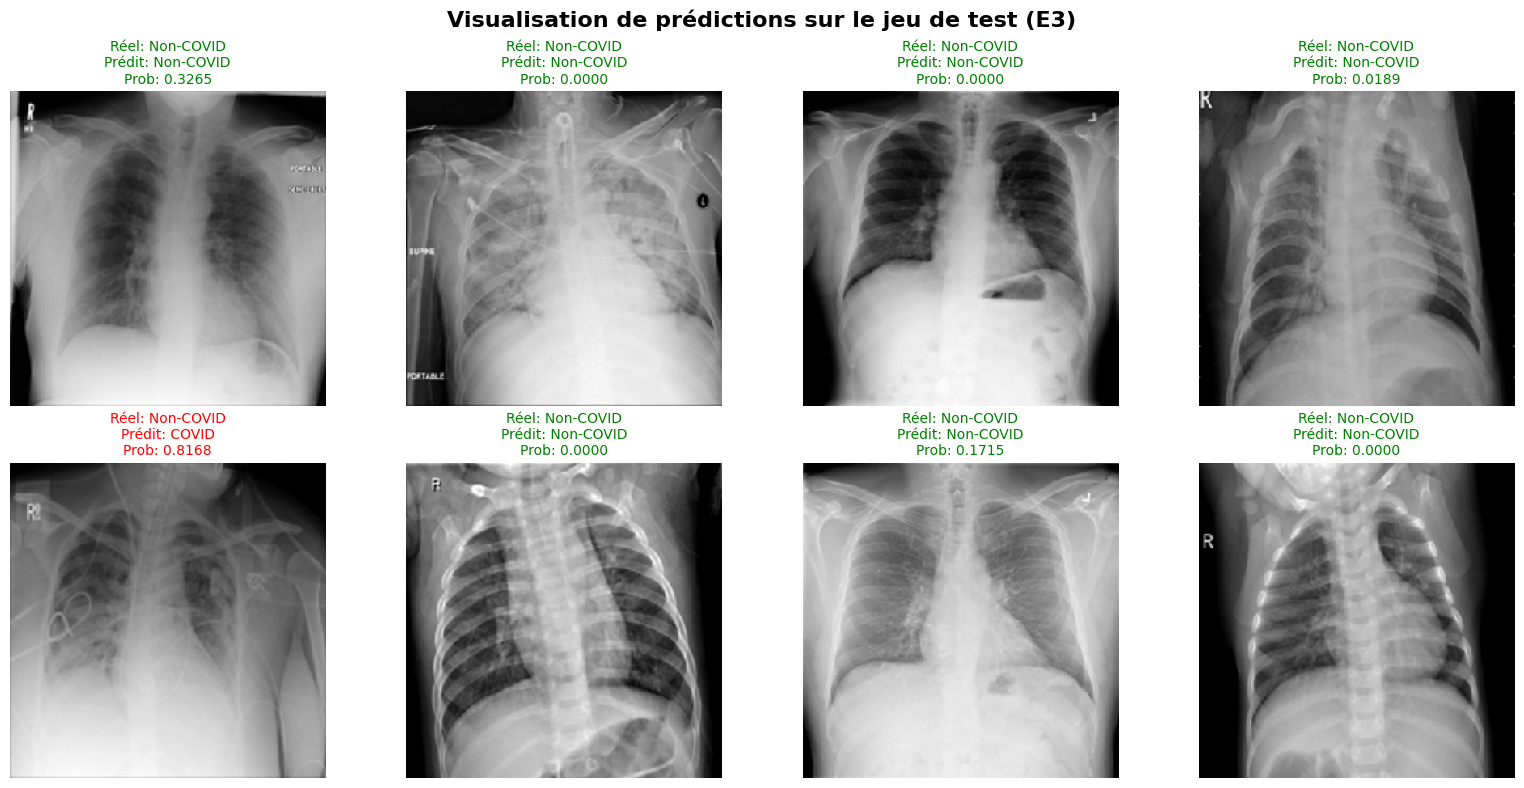

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Charger les prédictions détaillées sauvegardées pour le jeu de test
predictions_df = pd.read_csv(OUTPUT_DIR / "E3_predictions_test.csv")

# Sélectionner aléatoirement 8 images à afficher
sample_df = predictions_df.sample(n=8, random_state=42)

plt.figure(figsize=(16, 8))

for i, (_, row) in enumerate(sample_df.iterrows()):
    img_path = row['filepath']
    true_label = "COVID" if int(row['y_true']) == 1 else "Non-COVID"
    pred_label = "COVID" if int(row['y_pred']) == 1 else "Non-COVID"
    proba = row['y_proba']

    # Charger et préparer l'image pour affichage
    try:
        img = load_img(img_path, target_size=(224, 224), color_mode="grayscale")
        plt.subplot(2, 4, i + 1)
        plt.imshow(img, cmap="gray")

        # Couleur verte pour une prédiction correcte, rouge si elle est incorrecte
        color = 'green' if true_label == pred_label else 'red'

        plt.title(f"Réel: {true_label}\nPrédit: {pred_label}\nProb: {proba:.4f}", color=color, fontsize=10)
        plt.axis('off')
    except Exception as e:
        print(f"Impossible de charger l'image {img_path}: {e}")

plt.suptitle("Visualisation de prédictions sur le jeu de test (E3)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [19]:
import pandas as pd

# Charger les rapports de performance sauvegardés
val_report = pd.read_csv(OUTPUT_DIR / "E3_classification_report_validation.csv", index_col=0)
test_report = pd.read_csv(OUTPUT_DIR / "E3_classification_report_test.csv", index_col=0)

# Extraction des métriques cibles pour la comparaison
metrics_to_compare = ['Non-COVID', 'COVID', 'accuracy', 'macro avg']
comparison_data = []

for metric in metrics_to_compare:
    if metric in val_report.index and metric in test_report.index:
        if metric == 'accuracy':
            comparison_data.append({
                'Métrique': 'Global Accuracy',
                'Validation': val_report.loc['accuracy', 'precision'],  # Keras/sklearn stocke l'accuracy dans la col precision
                'Test': test_report.loc['accuracy', 'precision'],
                'Différence (Test - Val)': test_report.loc['accuracy', 'precision'] - val_report.loc['accuracy', 'precision']
            })
        else:
            for col in ['precision', 'recall', 'f1-score']:
                val_val = val_report.loc[metric, col]
                test_val = test_report.loc[metric, col]
                label_name = f"{metric} ({col.capitalize()})"
                comparison_data.append({
                    'Métrique': label_name,
                    'Validation': val_val,
                    'Test': test_val,
                    'Différence (Test - Val)': test_val - val_val
                })

# Convertir en DataFrame pour un affichage propre
comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.style.format({
    'Validation': '{:.4f}',
    'Test': '{:.4f}',
    'Différence (Test - Val)': '{:+.4f}'
}).set_caption("Comparaison des performances : Validation vs Test (Modèle E3)"))

,Métrique,Validation,Test,Différence (Test - Val)
0,Non-COVID (Precision),0.9850,0.9882,+0.0032
1,Non-COVID (Recall),0.9598,0.9567,-0.0031
2,Non-COVID (F1-score),0.9722,0.9722,-0.0000
3,COVID (Precision),0.8264,0.8180,-0.0085
4,COVID (Recall),0.9292,0.9447,+0.0155
5,COVID (F1-score),0.8748,0.8768,+0.0020
6,Global Accuracy,0.9545,0.9546,+0.0001
7,macro avg (Precision),0.9057,0.9031,-0.0026
8,macro avg (Recall),0.9445,0.9507,+0.0062
9,macro avg (F1-score),0.9235,0.9245,+0.0010


### 📊 Benchmark global des performances de l'expérience E3
Ce tableau synthétise les métriques clés de l'expérience **E3** (avec suréchantillonnage de la classe minoritaire et augmentation d'images contrôlée) sur les jeux de Validation et de Test.

In [20]:
import pandas as pd

# Construction du tableau de benchmark consolidé
benchmark_data = {
    'Partition': ['Validation', 'Test', 'Validation', 'Test', 'Validation', 'Test'],
    'Classe': ['Globale', 'Globale', 'COVID', 'COVID', 'Non-COVID', 'Non-COVID'],
    'Exactitude (Accuracy)': [0.9545, 0.9546, None, None, None, None],
    'Précision': [None, None, 0.8264, 0.8180, 0.9850, 0.9882],
    'Rappel (Recall)': [None, None, 0.9292, 0.9447, 0.9598, 0.9567],
    'F1-Score': [None, None, 0.8748, 0.8768, 0.9722, 0.9722]
}

benchmark_df = pd.DataFrame(benchmark_data)
display(benchmark_df.style.highlight_null(color='lightgrey').set_caption("E3 Benchmark Summary Table"))

,Partition,Classe,Exactitude (Accuracy),Précision,Rappel (Recall),F1-Score
0,Validation,Globale,0.954500,nan,nan,nan
1,Test,Globale,0.954600,nan,nan,nan
2,Validation,COVID,nan,0.826400,0.929200,0.874800
3,Test,COVID,nan,0.818000,0.944700,0.876800
4,Validation,Non-COVID,nan,0.985000,0.959800,0.972200
5,Test,Non-COVID,nan,0.988200,0.956700,0.972200
